# Notebook 06 — Historical Landslide Multi-Trigger Analysis
**Malaysia Landslide Susceptibility Decision-Support Dashboard | Exploratory investigation only**

**Scope:** Audit historical source descriptions, retain multi-label reported triggers, link only verified event identifiers, compare *pre-event* environmental measurements, and flag compatibility for unknown-trigger records. **Does not train or change the existing susceptibility classifier**, inventory, pseudo-absences, folds or trained models.

**Interpretation safeguards:** (1) Reported triggers are not proven causes. (2) Missing triggers are unknown, not negative. (3) Event-level linkage requires an explicit unique identifier, not proximity. (4) Environmental compatibility is not causal attribution. (5) No event trigger or post-event feature may enter the primary binary susceptibility classifier. (6) Unmatched original source rows are retained separately, not silently assigned to processed events.

**Before running:** Place the notebook in `notebooks/` of your FYP repository. Review `SOURCE_OVERRIDE`, `MANUAL_ID_CROSSWALK`, and `TRIGGER_OVERRIDE` in section 0. Unlike the original pipelines, this notebook is read-only outside its dedicated output folder.

## 0. Configuration and reproducibility
Discover project paths from the existing Notebook 02/03 directory layout. Every data input is read-only; outputs go exclusively to `outputs/historical_trigger_analysis/`.

In [1]:
from pathlib import Path
import re, json, hashlib, unicodedata, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT=next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p/'data'/'processed'/'inventory').is_dir()),None)
if ROOT is None: raise FileNotFoundError('Open notebook from the Landslide_FYP project, containing data/processed/inventory/')
INVENTORY=ROOT/'data/processed/inventory/event_candidates.csv'
FEATURES=ROOT/'data/processed/features/environmental_features.csv'
STATIC=ROOT/'data/processed/modelling/static_model_dataset.csv'
TEMPORAL=ROOT/'data/processed/modelling/temporal_model_dataset.csv'
ENHANCEMENT=ROOT/'data/processed/features/historical_environmental_enhancement_recovery_REVIEW.csv'
if not ENHANCEMENT.exists(): ENHANCEMENT=ROOT/'data/processed/features/historical_environmental_enhancement.csv'
OUT=ROOT/'outputs/historical_trigger_analysis'; FIG=OUT/'figures'; FIG.mkdir(parents=True,exist_ok=True)
# Explicit path/column overrides are preferred when automated discovery is ambiguous.
SOURCE_OVERRIDE={'COOLR':None,'GFLD':None,'JMG_original':None,'JMG_archive':None}
TRIGGER_OVERRIDE={}  # e.g. {'COOLR':'trigger'}; never guess an irrelevant field
MANUAL_ID_CROSSWALK=None  # Optional analyst-verified CSV with source, source_record_id, event_candidate_id
# Do NOT infer identity from nearest coordinates or sequential row order.
SOURCE_PATTERNS={'COOLR':('coolr','nasa_coolr'),'GFLD':('gfld','global_fatal_landslide'),
                 'JMG_original':('jmg_government_raw','jmg_original','original_jmg'),
                 'JMG_archive':('jmg_archive_2021_2022','archive_2021_2022')}
REJECT_FILENAME=('checkpoint','audit','summary','matched','candidate','model','processed','output','backup')
pd.set_option('display.max_columns',45)
print('ROOT:',ROOT,'\nOUTPUT:',OUT)
for label,p in [('inventory',INVENTORY),('environmental',FEATURES),('static',STATIC),('temporal',TEMPORAL),('enhancement',ENHANCEMENT)]:print(label,p.exists(),p)
if not INVENTORY.exists():raise FileNotFoundError(f'Run Notebook 01 first: {INVENTORY}')

ROOT: C:\landslide_fyp 
OUTPUT: C:\landslide_fyp\outputs\historical_trigger_analysis
inventory True C:\landslide_fyp\data\processed\inventory\event_candidates.csv
environmental True C:\landslide_fyp\data\processed\features\environmental_features.csv
static True C:\landslide_fyp\data\processed\modelling\static_model_dataset.csv
temporal True C:\landslide_fyp\data\processed\modelling\temporal_model_dataset.csv
enhancement True C:\landslide_fyp\data\processed\features\historical_environmental_enhancement_recovery_REVIEW.csv


## 1. Inventory provenance, source discovery and data-quality audit
The latest *processed event candidates* are the authoritative universe for this investigation. These may include records that were not eligible for the final static or temporal modelling cohorts; report that distinction explicitly. A processed candidate is not automatically a unique physical landslide if original deduplication was provisional.

Raw-file discovery is **conservative** and reports ambiguity. Raw totals represent source-file rows; they must never be summed to claim unique events.

In [2]:
def read_any(p):
    if p.suffix.lower()=='.csv': return pd.read_csv(p,low_memory=False)
    if p.suffix.lower() in ('.xlsx','.xls'):return pd.read_excel(p)
    if p.suffix.lower() in ('.geojson','.json'):
        import geopandas as gpd
        return pd.DataFrame(gpd.read_file(p).drop(columns=['geometry'],errors='ignore'))
    raise ValueError('Unsupported table '+str(p))
def norm(s):return re.sub(r'[^a-z0-9]+','_',unicodedata.normalize('NFKD',str(s)).lower()).strip('_')
def pick(df, candidates):
    d={norm(c):c for c in df.columns}
    return next((d[norm(x)] for x in candidates if norm(x) in d),None)
def discover_source(name):
    override=SOURCE_OVERRIDE[name]
    if override:
        p=Path(override);p=p if p.is_absolute() else ROOT/p
        if not p.exists():raise FileNotFoundError(p)
        return p, [str(p)]
    bases=[ROOT/'data/raw/inventory',ROOT/'data/raw',ROOT/'data/processed/inventory']
    seen={}
    for base in bases:
        if base.exists():
            for ext in ('*.csv','*.geojson','*.xlsx'):
                for p in base.rglob(ext):
                    name_low=p.name.lower()
                    if any(t in name_low for t in SOURCE_PATTERNS[name]) and not any(t in name_low for t in REJECT_FILENAME):seen[str(p.resolve())]=p
    matches=sorted(seen.values(),key=lambda p:str(p))
    if name=='GFLD':
        valid=[p for p in matches if 'validated' in p.name.lower()]
        matches=valid if valid else matches
    return (matches[0] if len(matches)==1 else None), [str(p) for p in matches]
inv=pd.read_csv(INVENTORY,low_memory=False)
assert 'event_candidate_id' in inv and inv.event_candidate_id.notna().all() and inv.event_candidate_id.is_unique,'Processed event candidate IDs must be unique'
assert 'source' in inv,'Processed inventory missing source'
inv['event_candidate_id']=inv.event_candidate_id.astype(str)
source_raw={}; files_audit=[]
for name in SOURCE_PATTERNS:
    p,matches=discover_source(name)
    rec={'source':name,'selected_path':str(p) if p else '', 'candidates_found':len(matches),'candidate_paths':' | '.join(matches),'status':'OK' if p else ('AMBIGUOUS_SET_OVERRIDE' if matches else 'NOT_FOUND')}
    if p:
        try:source_raw[name]=read_any(p);rec['raw_rows']=len(source_raw[name]);rec['columns']=' | '.join(map(str,source_raw[name].columns))
        except Exception as exc:rec['status']='READ_FAILED';rec['error']=str(exc)
    files_audit.append(rec)
file_audit=pd.DataFrame(files_audit); display(file_audit[['source','status','raw_rows','selected_path']] if 'raw_rows' in file_audit else file_audit)
file_audit.to_csv(OUT/'01_source_file_discovery.csv',index=False)
print('Processed candidate rows:',len(inv),'| by source:');display(inv.source.value_counts(dropna=False).rename_axis('processed_source').reset_index(name='rows'))
print('Inventory columns:',inv.columns.tolist())
print('NOTE: Correct the source overrides and rerun if an expected raw source was not uniquely located.')

,source,status,raw_rows,selected_path
0,COOLR,NOT_FOUND,NaN,
1,GFLD,AMBIGUOUS_SET_OVERRIDE,NaN,
2,JMG_original,OK,52.0,C:\landslide_fyp\data\raw\inventory\JMG\JMG_Go...
3,JMG_archive,OK,366.0,C:\landslide_fyp\data\raw\inventory\JMG_Archiv...


Processed candidate rows: 713 | by source:


,processed_source,rows
0,JMG_archive,364
1,COOLR,236
2,GFLD,61
3,JMG_original,52


Inventory columns: ['record_uid', 'source', 'source_row', 'source_identifier', 'original_date_value', 'event_date', 'date_precision', 'reported_year', 'state_raw', 'district_raw', 'location_raw', 'longitude_candidate', 'latitude_candidate', 'projected_x_raw', 'projected_y_raw', 'coordinate_status', 'coordinate_method', 'coordinate_crs', 'source_geometry_match_m', 'native_source_file', 'quality_flags', 'flag_count', 'jmg_original_control_uid', 'jmg_raw_control_distance_m', 'jmg_wgs_control_distance_m', 'jmg_control_check_status', 'malaysia_polygon_status', 'geographic_verification_level', 'geographic_review_required', 'coordinate_usable_for_preliminary_spatial_review', 'duplicate_candidate_links', 'duplicate_review_status', 'state_standard', 'district_standard', 'location_standard', 'exact_row_representative_uid', 'exact_repeated_copy', 'candidate_pair_flag', 'archive_crs_evidence_level', 'archive_crs_hypothesis', 'strong_cross_source_duplicate_candidate', 'archive_matches_original_cont

## 2. Identify source triggers and establish safe event-level mappings
A raw source row can be linked to an event **only** if it already contains the exact curated `event_candidate_id`, or has an *explicitly verified* crosswalk. Source-native IDs are not assumed interchangeable with curated IDs. Raw rows that cannot be matched remain in the raw audit; trigger content is never transferred by nearest-coordinate heuristics.

If your Notebook 01 generated a native-to-curated ID mapping, export its checked table to a three-column `source`, `source_record_id`, `event_candidate_id` CSV and set `MANUAL_ID_CROSSWALK`.

In [3]:
TRIGGER_COL_NAMES=['trigger','triggers','trigger_type','triggering_factor','triggering_factors','trigger_description','reported_trigger','landslide_trigger','cause','causes','cause_of_landslide','landslide_cause','punca','punca_kejadian','faktor_penyebab','faktor','penyebab','sebab']
EVENT_ID_NAMES=['event_candidate_id','curated_event_id']
RAW_ID_NAMES=['source_record_id','record_id','event_id','landslide_id','id','objectid','fid']
DATE_NAMES=['event_date','date','eventdate','landslide_date','occurrence_date','tarikh','tarikh_kejadian']
LAT_NAMES=['latitude','latitude_candidate','lat','y']; LON_NAMES=['longitude','longitude_candidate','lon','long','x']
AREA_NAMES=['state','negeri','district','daerah','location','lokasi']

def trigger_columns(d,source):
    if source in TRIGGER_OVERRIDE:
        v=TRIGGER_OVERRIDE[source]
        if v not in d: raise KeyError(f'{source} override trigger column {v!r} not found')
        return [v]
    return [c for c in d if norm(c) in {norm(t) for t in TRIGGER_COL_NAMES}]
all_sources={'PROCESSED':inv,**source_raw}
schema=[]
for name,d in all_sources.items():
    schema.append({'source':name,'rows':len(d),'trigger_columns':' | '.join(trigger_columns(d,name)),
      'curated_id_col':pick(d,EVENT_ID_NAMES),'raw_id_col':pick(d,RAW_ID_NAMES),
      'date_col':pick(d,DATE_NAMES),'lon_col':pick(d,LON_NAMES),'lat_col':pick(d,LAT_NAMES),
      'area_col':pick(d,AREA_NAMES)})
schema_df=pd.DataFrame(schema);display(schema_df);schema_df.to_csv(OUT/'02_raw_and_processed_schema_audit.csv',index=False)
if MANUAL_ID_CROSSWALK:
    cross=pd.read_csv(MANUAL_ID_CROSSWALK,dtype=str)
    assert {'source','source_record_id','event_candidate_id'}.issubset(cross),'Crosswalk schema must be source/source_record_id/event_candidate_id'
    assert not cross.duplicated(['source','source_record_id']).any(),'Duplicate source-native IDs in crosswalk'
    assert cross.event_candidate_id.isin(inv.event_candidate_id).all(),'Crosswalk target not in processed inventory'
else: cross=pd.DataFrame(columns=['source','source_record_id','event_candidate_id'])

def make_text(df,cols):
    if not cols:return pd.Series('',index=df.index,dtype='object')
    return df[cols].fillna('').astype(str).apply(lambda r:' | '.join(x.strip() for x in r if x.strip() and x.strip().lower() not in ('nan','none','null','unknown','n/a','-')),axis=1)
raw_long=[]; matching=[]
for src,d in source_raw.items():
    cols=trigger_columns(d,src); x=pd.DataFrame({'source':src,'row_index':np.arange(len(d)), 'original_trigger_text':make_text(d,cols)})
    eid=pick(d,EVENT_ID_NAMES); rid=pick(d,RAW_ID_NAMES)
    x['source_record_id']=d[rid].astype('string').values if rid else pd.Series(pd.NA,index=x.index,dtype='string')
    x['event_candidate_id']=pd.Series(pd.NA,index=x.index,dtype='string')
    x['mapping_method']='UNMATCHED'
    if eid:
        ids=d[eid].astype('string'); good=ids.isin(inv.event_candidate_id)&~ids.duplicated(keep=False)
        x.loc[good,'event_candidate_id']=ids[good].to_numpy();x.loc[good,'mapping_method']='DIRECT_UNIQUE_CURATED_ID'
    if rid and not cross.empty:
        cc=cross[cross.source.eq(src)]
        if not cc.empty:
            cc=cc.rename(columns={'event_candidate_id':'mapped_id'})
            x=x.merge(cc[['source','source_record_id','mapped_id']],on=['source','source_record_id'],how='left',validate='many_to_one')
            use=x.mapped_id.notna()&x.event_candidate_id.isna()
            x.loc[use,'event_candidate_id']=x.loc[use,'mapped_id'];x.loc[use,'mapping_method']='VERIFIED_CROSSWALK'
            x=x.drop(columns='mapped_id')
    # Refuse contradictory many-raw-to-one-event mappings within one source unless manually investigated.
    dup=x.event_candidate_id.notna() & x.event_candidate_id.duplicated(keep=False)
    x.loc[dup,'mapping_method']='AMBIGUOUS_DUPLICATE_EVENT_ID';x.loc[dup,'event_candidate_id']=pd.NA
    raw_long.append(x)
raw=pd.concat(raw_long,ignore_index=True) if raw_long else pd.DataFrame(columns=['source','row_index','source_record_id','event_candidate_id','mapping_method','original_trigger_text'])
# Processed trigger text is authoritative when present; known raw descriptions are supplemental, never overwrite.
processed_text=make_text(inv,trigger_columns(inv,'PROCESSED'))
master=inv[['event_candidate_id','source']].copy();master['processed_trigger_text']=processed_text.values
if 'event_date' in inv:master['event_date']=inv.event_date.values
for f in ['date_precision','longitude_candidate','latitude_candidate','state','district','static_candidate','temporal_candidate']:
    if f in inv:master[f]=inv[f].values
valid_raw=raw[raw.event_candidate_id.notna() & raw.original_trigger_text.ne('')].copy()
aggregated=valid_raw.groupby('event_candidate_id').agg(raw_trigger_text=('original_trigger_text',lambda s:' | '.join(sorted(set(s)))),raw_trigger_sources=('source',lambda s:' | '.join(sorted(set(s))))).reset_index()
master=master.merge(aggregated,on='event_candidate_id',how='left',validate='one_to_one')
master['original_trigger_text']=master.processed_trigger_text.where(master.processed_trigger_text.ne(''),master.raw_trigger_text.fillna(''))
master['reported_text_provenance']=np.select([master.processed_trigger_text.ne(''),master.raw_trigger_text.notna()],['PROCESSED','LINKED_RAW'],default='UNAVAILABLE')
raw['reported_text_present']=raw.original_trigger_text.ne('')
print('Raw records with verified links:',int(raw.event_candidate_id.notna().sum()),'/',len(raw))
print('Processed candidates with reported trigger text:',int(master.original_trigger_text.ne('').sum()),'/',len(master))
raw.to_csv(OUT/'03_raw_trigger_matching_audit.csv',index=False)
# Row counts by source are raw-file totals, not deduplicated cases.
audit=raw.groupby('source',dropna=False).agg(raw_records=('row_index','size'),raw_with_reported_trigger=('reported_text_present','sum'),verified_linked_rows=('event_candidate_id','count')).reset_index() if len(raw) else pd.DataFrame(columns=['source','raw_records','raw_with_reported_trigger','verified_linked_rows'])
audit['raw_missing_or_unknown']=audit.raw_records-audit.raw_with_reported_trigger
audit['raw_trigger_availability_pct']=np.where(audit.raw_records.gt(0),100*audit.raw_with_reported_trigger/audit.raw_records,np.nan)
processed_counts=master.groupby('source',dropna=False).agg(processed_candidates=('event_candidate_id','size'),processed_with_reported_trigger=('original_trigger_text',lambda s:s.ne('').sum())).reset_index().rename(columns={'source':'processed_source'})
display(audit);display(processed_counts)
audit.to_csv(OUT/'04_raw_source_trigger_availability.csv',index=False);processed_counts.to_csv(OUT/'05_processed_source_trigger_availability.csv',index=False)

,source,rows,trigger_columns,curated_id_col,raw_id_col,date_col,lon_col,lat_col,area_col
0,PROCESSED,713,,event_candidate_id,NaN,event_date,longitude_candidate,latitude_candidate,NaN
1,JMG_original,52,Punca__,NaN,ID__,NaN,NaN,NaN,Negeri
2,JMG_archive,366,,NaN,NaN,Tarikh,NaN,NaN,Negeri


Raw records with verified links: 0 / 418
Processed candidates with reported trigger text: 0 / 713


,source,raw_records,raw_with_reported_trigger,verified_linked_rows,raw_missing_or_unknown,raw_trigger_availability_pct
0,JMG_archive,366,0,0,366,0.000000
1,JMG_original,52,3,0,49,5.769231


,processed_source,processed_candidates,processed_with_reported_trigger
0,COOLR,236,0
1,GFLD,61,0
2,JMG_archive,364,0
3,JMG_original,52,0


## 3. Standardise multi-label reported triggers (English and Malay)
The rule dictionary is deliberately reviewable; negation is screened conservatively. **Unknown is not an explicit negative label.** Ambiguous terms are flagged for human review rather than automatically assigned. Original descriptions are always retained.

,category,events,share_of_all_processed_pct
0,Rainfall,0,0.0
1,Human_activity,0,0.0
2,Drainage,0,0.0
3,Geological,0,0.0
4,Other_natural,0,0.0


Multi-label events: 0 | Needs human review: 0


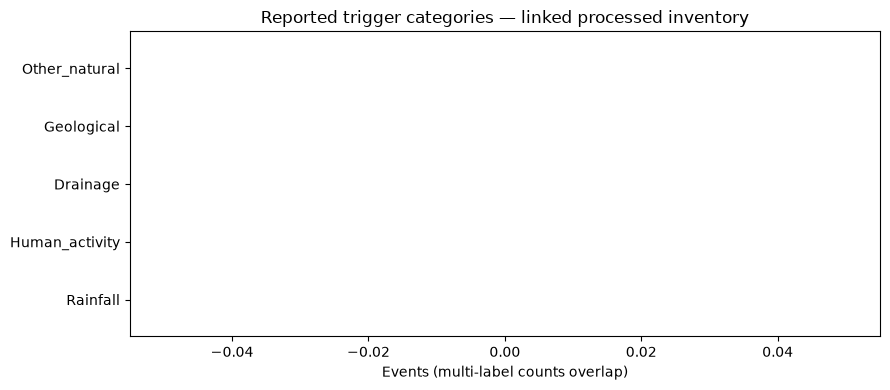

In [4]:
RULES={
 'Rainfall':r'\b(?:rain|rainfall|heavy\s+rain|downpour|monsoon|prolonged\s+rain|continuous\s+rain|hujan|hujan\s+lebat|hujan\s+berterusan|ribut\s+hujan)\b',
 'Human_activity':r'\b(?:construction|excavat(?:ion|ing)|mining|quarry|hill\s+cutting|slope\s+cutting|earthwork|deforestation|logging|land\s+clearing|pembinaan|pengorekan|perlombongan|kuari|pemotongan\s+bukit|kerja\s+tanah|pembalakan)\b',
 'Drainage':r'\b(?:drainage|drain|blocked\s+drain|culvert|flood(?:ing)?|saliran|perparitan|longkang|tersumbat|banjir)\b',
 'Geological':r'\b(?:geolog(?:y|ical)|fault(?:ing)?|weathered\s+rock|weak\s+rock|soil\s+instability|ground\s+condition|geologi|batuan|sesar|tanah\s+tidak\s+stabil)\b',
 'Other_natural':r'\b(?:earthquake|seismic|tropical\s+cyclone|typhoon|gempa|taufan)\b'
}
NEGATION=re.compile(r'\b(?:no|not|without|tiada|bukan|tidak|none)\b',re.I)
UNCERTAIN=re.compile(r'\b(?:possible|possibly|suspect(?:ed)?|might|may|berkemungkinan|mungkin|disyaki)\b',re.I)
UNKNOWN=re.compile(r'^(?:\s*|unknown|not\s+reported|not\s+available|n/?a|tiada\s+maklumat|tidak\s+diketahui|unspecified|-)\s*$',re.I)
def classify_report(s):
    t=str(s or '').strip().lower()
    if UNKNOWN.fullmatch(t):return {'labels':[],'status':'UNKNOWN','needs_review':False}
    matches=[];review=bool(UNCERTAIN.search(t))
    for label,pattern in RULES.items():
        for m in re.finditer(pattern,t,re.I):
            left=t[max(0,m.start()-35):m.start()];left=re.split(r'[;,.|]',left)[-1]
            if NEGATION.search(left):review=True;continue
            matches.append(label)
    matches=sorted(set(matches))
    return {'labels':matches,'status':'REPORTED_CATEGORY_MATCH' if matches else 'OTHER_UNSPECIFIED','needs_review':review or not bool(matches)}
classified=master.original_trigger_text.apply(classify_report)
master['trigger_labels']=classified.map(lambda x:' | '.join(x['labels']))
master['trigger_status']=classified.map(lambda x:x['status']);master['needs_manual_review']=classified.map(lambda x:x['needs_review'])
for k in RULES:master['trigger_'+k]=classified.map(lambda x:k in x['labels'])
master['reported_label_count']=classified.map(lambda x:len(x['labels']))
master['multi_trigger']=master.reported_label_count.ge(2)
master['has_reported_text']=master.original_trigger_text.ne('')
# Multi-label frequencies are not mutually exclusive; percentages may total > 100%.
freq=pd.DataFrame([{'category':k,'events':int(master['trigger_'+k].sum()),'share_of_all_processed_pct':100*master['trigger_'+k].mean()} for k in RULES]);display(freq)
print('Multi-label events:',master.multi_trigger.sum(),'| Needs human review:',master.needs_manual_review.sum())
master.to_csv(OUT/'06_processed_events_reported_multilabel_triggers.csv',index=False)
freq.to_csv(OUT/'07_multilabel_trigger_frequencies.csv',index=False)
review=master[master.needs_manual_review & master.has_reported_text][['event_candidate_id','source','original_trigger_text','trigger_labels','trigger_status']]
review.to_csv(OUT/'08_manual_trigger_coding_review.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4));ax.barh(freq.category,freq.events);ax.set(xlabel='Events (multi-label counts overlap)',title='Reported trigger categories — linked processed inventory');fig.tight_layout();fig.savefig(FIG/'01_reported_trigger_categories.png',dpi=180);plt.show()

## 4. Inventory, date, geographic and environmental coverage
The environmental-feature file is event-level. The modelling CSVs contain positive and background records, but only `target==1` is eligible for this **historical triggering** exploration. Sidecar enhancement rows are joined on `sample_id` only, with one-to-one validation. **Do not use background controls as historical trigger observations.**

Dates with year-only/month-only precision must not receive event-specific antecedent rainfall interpretations.

In [5]:
feature=pd.read_csv(FEATURES,low_memory=False) if FEATURES.exists() else pd.DataFrame()
if len(feature):
    assert 'event_candidate_id' in feature and feature.event_candidate_id.is_unique,'Environmental features must have unique curated IDs'
    fcols=[x for x in feature.columns if x not in master.columns or x=='event_candidate_id']
    master=master.merge(feature[fcols],on='event_candidate_id',how='left',validate='one_to_one',indicator='_feature_match')
    master['environmental_feature_matched']=master._feature_match.eq('both');master=master.drop(columns='_feature_match')
else:master['environmental_feature_matched']=False
positive_sets=[]
for branch,p in [('static',STATIC),('temporal',TEMPORAL)]:
    if p.exists():
        t=pd.read_csv(p,low_memory=False);assert {'target','event_candidate_id','sample_id'}.issubset(t),'Model data missing matching keys'
        c=t[t.target.eq(1)].copy();assert c.sample_id.is_unique
        c['model_branch']=branch;positive_sets.append(c)
        master['in_'+branch+'_model']=master.event_candidate_id.isin(c.event_candidate_id.astype(str))
    else:master['in_'+branch+'_model']=False
if positive_sets:
    model_cases=pd.concat(positive_sets,ignore_index=True)
    if ENHANCEMENT.exists():
        e=pd.read_csv(ENHANCEMENT,low_memory=False); assert 'sample_id' in e and e.sample_id.is_unique
        add=['sample_id']+[c for c in e if c not in model_cases.columns and c not in ('matched_event_id','_key')]
        model_cases=model_cases.merge(e[add],on='sample_id',how='left',validate='many_to_one')
    model_cases.to_csv(OUT/'09_positive_model_case_feature_audit.csv',index=False)
else:model_cases=pd.DataFrame()
if 'event_date' in master:
    master['event_date_parsed']=pd.to_datetime(master.event_date,errors='coerce')
    master['event_year']=master.event_date_parsed.dt.year
else:master['event_date_parsed']=pd.NaT;master['event_year']=np.nan
if 'date_precision' in master:
    master['is_day_precise']=master.date_precision.astype(str).str.lower().isin(['day','daily','exact','day_precision'])
else:master['is_day_precise']=False
# Source and year coverage are descriptive. Missing year is retained.
cover=master.groupby('source',dropna=False).agg(total_candidates=('event_candidate_id','size'),reported_text=('has_reported_text','sum'),coded_category=('reported_label_count',lambda s:s.gt(0).sum()),multi_trigger=('multi_trigger','sum'),environmental_matched=('environmental_feature_matched','sum'),day_precise=('is_day_precise','sum')).reset_index()
cover['reported_text_pct']=100*cover.reported_text/cover.total_candidates
display(cover);cover.to_csv(OUT/'10_processed_source_coverage.csv',index=False)
by_year=master.groupby(['source','event_year'],dropna=False).agg(events=('event_candidate_id','size'),reported=('has_reported_text','sum')).reset_index();by_year.to_csv(OUT/'11_source_year_missingness.csv',index=False)
area_col=next((x for x in ['state','state_name','negeri','district','daerah'] if x in master),None)
if area_col:
    by_area=master.groupby(['source',area_col],dropna=False).agg(events=('event_candidate_id','size'),reported=('has_reported_text','sum')).reset_index();by_area.to_csv(OUT/'12_source_area_missingness.csv',index=False)
else:print('No validated administrative area column in processed table; geographic stratification skipped.')
print('CAUTION: event_date_parsed is not proof of day-level precision; check the original date_precision codes before using rainfall.')
print('Observed date_precision values:',master.date_precision.value_counts(dropna=False).head(20).to_dict() if 'date_precision' in master else 'COLUMN ABSENT')

C:\Users\User\AppData\Local\Temp\ipykernel_24848\1463704792.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  master=master.merge(feature[fcols],on='event_candidate_id',how='left',validate='one_to_one',indicator='_feature_match')
C:\Users\User\AppData\Local\Temp\ipykernel_24848\1463704792.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  master=master.merge(feature[fcols],on='event_candidate_id',how='left',validate='one_to_one',indicator='_feature_match')
C:\Users\User\AppData\Local\Temp\ipykernel_24848\1463704792.py:6: Perf

,source,total_candidates,reported_text,coded_category,multi_trigger,environmental_matched,day_precise,reported_text_pct
0,COOLR,236,0,0,0,236,0,0.0
1,GFLD,61,0,0,0,61,0,0.0
2,JMG_archive,364,0,0,0,364,361,0.0
3,JMG_original,52,0,0,0,52,47,0.0


No validated administrative area column in processed table; geographic stratification skipped.
CAUTION: event_date_parsed is not proof of day-level precision; check the original date_precision codes before using rainfall.
Observed date_precision values: {'day': 408, 'day_timestamp_field': 297, 'year_only': 4, 'month_year': 2, 'invalid_components': 2}


## 5. Descriptive environmental comparisons by *reported* trigger
**No hypothesis tests or causal claims.** For rainfall, runoff and soil moisture, include only records with verified day-precision dates and valid pre-event feature provenance. Where the data were extracted using a same-day or post-event window, **exclude that feature until its time-window bounds are checked against Notebook 02**. The default list here is conservative and requires an explicit provenance confirmation for temporal variables.

In [6]:
STATIC_CANDIDATES=['elevation_m','slope_deg','aspect_deg','road_distance_m','waterway_distance_m','merit_hand_m','merit_upstream_area_km2',
                   'soil_clay_surface','soil_sand_surface','soil_silt_surface','soil_bdod_surface','ndvi_pre_event','ndvi_change_2y','forest_loss_5y_250m_pct',
                   'profile_curvature','plan_curvature','twi','spi','regional_fault_distance_m','major_fault_window_distance_m']
TEMPORAL_CANDIDATES=['rain_1d_mm','rain_3d_mm','rain_7d_mm','rain_14d_mm','rain_30d_mm','soil_moisture_7d_m3m3','runoff_7d_mm','runoff_30d_mm']
# Explicit opt-in ONLY after confirming temporal window bounds/reference-date consistency in Notebook 02.
PRE_EVENT_TEMPORAL_VERIFIED=False
if model_cases.empty:
    print('Model case CSV not available. Using direct event-level feature file; model sidecar-dependent measures unavailable.')
    analysis=master.copy()
else:
    # Give preference to temporal case rows when available; static cases cover events without temporal data.
    order={'temporal':0,'static':1}
    model_cases['_priority']=model_cases.model_branch.map(order)
    m=model_cases.sort_values('_priority').drop_duplicates('event_candidate_id')
    cols=['event_candidate_id']+[c for c in STATIC_CANDIDATES+TEMPORAL_CANDIDATES if c in m]
    m=m[cols]
    analysis=master.drop(columns=[c for c in STATIC_CANDIDATES+TEMPORAL_CANDIDATES if c in master and c in m]).merge(m,on='event_candidate_id',how='left',validate='one_to_one')
    # Fallback event-level measured predictors only for events absent from model cohorts.
    if len(feature):
        for col in STATIC_CANDIDATES+TEMPORAL_CANDIDATES:
            if col in feature:
                look=feature.set_index('event_candidate_id')[col]
                if col not in analysis:analysis[col]=analysis.event_candidate_id.map(look)
                else:analysis[col]=analysis[col].combine_first(analysis.event_candidate_id.map(look))
available_static=[x for x in STATIC_CANDIDATES if x in analysis]
available_temporal=[x for x in TEMPORAL_CANDIDATES if x in analysis]
print('Static feature columns:',available_static)
print('Temporal feature columns:',available_temporal)
print('Temporal comparisons ENABLED:',PRE_EVENT_TEMPORAL_VERIFIED)
if not PRE_EVENT_TEMPORAL_VERIFIED:print('Temporal feature summaries held back pending source-window/date verification (set flag True deliberately after confirmation).')
rows=[]
for cat in RULES:
    subset=analysis[analysis['trigger_'+cat]]
    for feat in available_static + (available_temporal if PRE_EVENT_TEMPORAL_VERIFIED else []):
        s=pd.to_numeric(subset[feat],errors='coerce')
        if feat in TEMPORAL_CANDIDATES:s=s[subset.is_day_precise]
        rows.append({'category':cat,'feature':feat,'reported_events':len(subset),'n_valid':int(s.notna().sum()),'median':s.median(),'q25':s.quantile(.25),'q75':s.quantile(.75),'mean':s.mean(),'source_count':subset.loc[s.dropna().index,'source'].nunique()})
summary=pd.DataFrame(rows);display(summary.sort_values(['category','feature']).head(40));summary.to_csv(OUT/'13_environmental_summaries_by_trigger.csv',index=False)
for feat in [x for x in ['slope_deg','elevation_m','road_distance_m','merit_hand_m','rain_7d_mm'] if x in analysis and (x not in TEMPORAL_CANDIDATES or PRE_EVENT_TEMPORAL_VERIFIED)]:
    groups=[pd.to_numeric(analysis.loc[analysis['trigger_'+cat],feat],errors='coerce').dropna().to_numpy() for cat in RULES]
    keep=[(cat,x) for cat,x in zip(RULES,groups) if len(x)>=3]
    if len(keep)<2:continue
    fig,ax=plt.subplots(figsize=(9,4.5));ax.boxplot([x for _,x in keep],tick_labels=[c for c,_ in keep],showfliers=False)
    ax.set(ylabel=feat,title=f'{feat}: reported categories (overlapping groups; non-causal)');ax.tick_params(axis='x',rotation=25);fig.tight_layout();fig.savefig(FIG/f'02_feature_{feat}.png',dpi=180);plt.show()
analysis.to_csv(OUT/'14_event_trigger_environmental_analysis.csv',index=False)

Static feature columns: ['elevation_m', 'slope_deg', 'aspect_deg', 'road_distance_m', 'waterway_distance_m', 'merit_hand_m', 'merit_upstream_area_km2', 'soil_clay_surface', 'soil_sand_surface', 'soil_silt_surface', 'soil_bdod_surface', 'ndvi_pre_event', 'ndvi_change_2y', 'forest_loss_5y_250m_pct', 'regional_fault_distance_m', 'major_fault_window_distance_m']
Temporal feature columns: ['rain_1d_mm', 'rain_3d_mm', 'rain_7d_mm', 'rain_14d_mm', 'rain_30d_mm', 'soil_moisture_7d_m3m3', 'runoff_7d_mm', 'runoff_30d_mm']
Temporal comparisons ENABLED: False
Temporal feature summaries held back pending source-window/date verification (set flag True deliberately after confirmation).


,category,feature,reported_events,n_valid,median,q25,q75,mean,source_count
34,Drainage,aspect_deg,0,0,NaN,NaN,NaN,NaN,0
32,Drainage,elevation_m,0,0,NaN,NaN,NaN,NaN,0
45,Drainage,forest_loss_5y_250m_pct,0,0,NaN,NaN,NaN,NaN,0
47,Drainage,major_fault_window_distance_m,0,0,NaN,NaN,NaN,NaN,0
37,Drainage,merit_hand_m,0,0,NaN,NaN,NaN,NaN,0
38,Drainage,merit_upstream_area_km2,0,0,NaN,NaN,NaN,NaN,0
44,Drainage,ndvi_change_2y,0,0,NaN,NaN,NaN,NaN,0
43,Drainage,ndvi_pre_event,0,0,NaN,NaN,NaN,NaN,0
46,Drainage,regional_fault_distance_m,0,0,NaN,NaN,NaN,NaN,0
35,Drainage,road_distance_m,0,0,NaN,NaN,NaN,NaN,0


## 6. Unknown-trigger environmental compatibility — conservative, transparent report
Only trigger-**compatible conditions**, never inferred causes. References are **reported-category environmental distributions**, which can be confounded by source, geography and reporting practice. A static slope/road distance cannot establish that rainfall or construction triggered a landslide.

Default rule: require event-level day precision, explicitly verified pre-event measurements, a minimum reference cohort, and an observed extreme versus a cross-source reference distribution. Otherwise return **Insufficient evidence**. This notebook intentionally does not manufacture confidence percentages.

In [7]:
# Descriptive screening thresholds are user-adjustable exploratory heuristics, not validated trigger classifiers.
MIN_REFERENCE_EVENTS=15; MIN_REFERENCE_SOURCES=2
unknown=analysis[~analysis.has_reported_text].copy()
if 'event_year' not in unknown:unknown['event_year']=np.nan
compat=[]
for _,r in unknown.iterrows():
    hits=[];evidence=[];caveats=[]
    if not bool(r.get('is_day_precise',False)):caveats.append('Unverified day-precision event date')
    if not PRE_EVENT_TEMPORAL_VERIFIED:caveats.append('Antecedent meteorological timing not verified')
    if PRE_EVENT_TEMPORAL_VERIFIED and bool(r.get('is_day_precise',False)):
        reference=analysis[analysis.trigger_Rainfall & analysis.is_day_precise]
        reference=reference[reference.source.ne(r.source)] # check external-source transferability
        if len(reference)>=MIN_REFERENCE_EVENTS and reference.source.nunique()>=MIN_REFERENCE_SOURCES:
            for f in ['rain_3d_mm','rain_7d_mm','rain_14d_mm','rain_30d_mm']:
                if f in reference and pd.notna(r.get(f)):
                    vals=pd.to_numeric(reference[f],errors='coerce').dropna()
                    if len(vals)>=MIN_REFERENCE_EVENTS and float(r[f])>=vals.quantile(.75):
                        hits.append('Rainfall-compatible');evidence.append(f'{f}={float(r[f]):.2f}, >= reference Q75={vals.quantile(.75):.2f}')
        else:caveats.append('Insufficient independent reported-rainfall reference cohort')
    # No static proxy is permitted to assert human construction or infrastructure drainage causation.
    compat.append({'event_candidate_id':r.event_candidate_id,'source':r.source,'event_date':r.get('event_date',np.nan),
         'original_reported_trigger':r.original_trigger_text,'observed_condition_screen': ' | '.join(sorted(set(hits))) if hits else 'Insufficient evidence',
         'supporting_environmental_evidence':' | '.join(evidence),'uncertainty_notes':' | '.join(caveats) if caveats else 'Exploratory; source bias and confounding remain',
         'independent_verification_status':'NOT_VERIFIED','inferred_cause':'NOT_ASSIGNED'})
compat=pd.DataFrame(compat);display(compat.head(15));compat.to_csv(OUT/'15_unknown_trigger_compatibility_report.csv',index=False)
print('Unknown reported-trigger records:',len(compat),'| sufficient evidence flags:',int(compat.observed_condition_screen.ne('Insufficient evidence').sum()) if len(compat) else 0)

,event_candidate_id,source,event_date,original_reported_trigger,observed_condition_screen,supporting_environmental_evidence,uncertainty_notes,independent_verification_status,inferred_cause
0,JMG_original:00001,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
1,JMG_original:00002,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
2,JMG_original:00003,JMG_original,2021-12-19,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
3,JMG_original:00004,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
4,JMG_original:00005,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
5,JMG_original:00006,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
6,JMG_original:00007,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
7,JMG_original:00008,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
8,JMG_original:00009,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
9,JMG_original:00010,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED


Unknown reported-trigger records: 713 | sufficient evidence flags: 0


## 7. Evidence quality, source bias and feature feasibility
Feature proposals must be measurable independently for **both landslide and matched background observations**, available at prediction time, and evaluated only under the **existing frozen geographic folds** if a later exploratory training experiment is justified.

In [8]:
quality=[]
for source,g in analysis.groupby('source',dropna=False):
    quality.append({'source':source,'processed_events':len(g),'reported_trigger_events':int(g.has_reported_text.sum()),
      'multi_label_events':int(g.multi_trigger.sum()),'manual_review_events':int(g.needs_manual_review.sum()),
      'day_precise_events':int(g.is_day_precise.sum()),'reporting_coverage_pct':100*g.has_reported_text.mean()})
quality=pd.DataFrame(quality);quality.to_csv(OUT/'16_source_reporting_quality.csv',index=False);display(quality)
features_to_consider=[
 ('max_rain_7d','Maximum daily antecedent rainfall in prior 7 days','Requires daily rain source, known event/control reference dates, pre-event windows','PENDING_DATA'),
 ('consecutive_wet_days','Consecutive wet days before reference date','Daily rainfall availability and predefined wet-day threshold','PENDING_DATA'),
 ('rainfall_anomaly','Antecedent rainfall anomaly versus historical local climatology','Historical baseline, reference-date matching, leakage-safe seasonal normal','PENDING_DATA'),
 ('rainfall_concentration','7-day/30-day antecedent rainfall concentration','Existing 7d and 30d rainfall; verify both windows end before event/reference date','TIMING_VERIFY'),
 ('rain_slope_interaction','Antecedent rainfall × slope interaction','Slope plus antecedent rainfall for positive and matched controls','TIMING_VERIFY'),
 ('rain_twi_interaction','Antecedent rainfall × TWI interaction','DEM-based TWI not confirmed and rainfall timing requires audit','MISSING_TWI'),
 ('profile_plan_curvature','Profile / plan curvature','Consistent DEM source/resolution, pre-event static extraction','NEW_EXTRACTION'),
 ('twi','Topographic Wetness Index','DEM flow-accumulation preprocessing; controls and cases; redundancy check against HAND/upstream area','NEW_EXTRACTION'),
 ('human_disturbance','Independently measured human disturbance','Historical construction/land use layers with temporal provenance; road distance alone insufficient','PENDING_DATA'),
 ('engineered_drainage','Engineered drainage condition','Historical drain network / capacity; natural TWI not a substitute','PENDING_DATA')]
feas=pd.DataFrame(features_to_consider,columns=['predictor','rationale','requirements','preliminary_status']);feas.to_csv(OUT/'17_candidate_predictor_feasibility.csv',index=False);display(feas)
assessment={'processed_event_candidates':int(len(master)),'trigger_reported_n':int(master.has_reported_text.sum()),
 'multi_trigger_n':int(master.multi_trigger.sum()),'unknown_trigger_n':int((~master.has_reported_text).sum()),
 'unmatched_raw_source_rows':int(raw.event_candidate_id.isna().sum()),'temporal_provenance_confirmed':bool(PRE_EVENT_TEMPORAL_VERIFIED),
 'suitable_for_automatic_trigger_classifier':'NOT_ESTABLISHED',
 'recommended_model_action':'NO RETRAINING FROM THIS NOTEBOOK; investigate trigger completeness and time provenance first',
 'validation_warning':'Previously inspected 5-km spatial folds support exploratory comparisons only; frozen historical holdout untouched'}
(OUT/'18_conclusion_and_safeguards.json').write_text(json.dumps(assessment,indent=2),encoding='utf-8')
print(json.dumps(assessment,indent=2));print('Outputs saved to',OUT)

,source,processed_events,reported_trigger_events,multi_label_events,manual_review_events,day_precise_events,reporting_coverage_pct
0,COOLR,236,0,0,0,0,0.0
1,GFLD,61,0,0,0,0,0.0
2,JMG_archive,364,0,0,0,361,0.0
3,JMG_original,52,0,0,0,47,0.0


,predictor,rationale,requirements,preliminary_status
0,max_rain_7d,Maximum daily antecedent rainfall in prior 7 days,"Requires daily rain source, known event/contro...",PENDING_DATA
1,consecutive_wet_days,Consecutive wet days before reference date,Daily rainfall availability and predefined wet...,PENDING_DATA
2,rainfall_anomaly,Antecedent rainfall anomaly versus historical ...,"Historical baseline, reference-date matching, ...",PENDING_DATA
3,rainfall_concentration,7-day/30-day antecedent rainfall concentration,Existing 7d and 30d rainfall; verify both wind...,TIMING_VERIFY
4,rain_slope_interaction,Antecedent rainfall × slope interaction,Slope plus antecedent rainfall for positive an...,TIMING_VERIFY
5,rain_twi_interaction,Antecedent rainfall × TWI interaction,DEM-based TWI not confirmed and rainfall timin...,MISSING_TWI
6,profile_plan_curvature,Profile / plan curvature,"Consistent DEM source/resolution, pre-event st...",NEW_EXTRACTION
7,twi,Topographic Wetness Index,DEM flow-accumulation preprocessing; controls ...,NEW_EXTRACTION
8,human_disturbance,Independently measured human disturbance,Historical construction/land use layers with t...,PENDING_DATA
9,engineered_drainage,Engineered drainage condition,Historical drain network / capacity; natural T...,PENDING_DATA


{
  "processed_event_candidates": 713,
  "trigger_reported_n": 0,
  "multi_trigger_n": 0,
  "unknown_trigger_n": 713,
  "unmatched_raw_source_rows": 418,
  "temporal_provenance_confirmed": false,
  "suitable_for_automatic_trigger_classifier": "NOT_ESTABLISHED",
  "recommended_model_action": "NO RETRAINING FROM THIS NOTEBOOK; investigate trigger completeness and time provenance first",
  "validation_warning": "Previously inspected 5-km spatial folds support exploratory comparisons only; frozen historical holdout untouched"
}
Outputs saved to C:\landslide_fyp\outputs\historical_trigger_analysis


## 8. What to report in FYP Chapter 4
1. **Data Understanding:** Source counts, reported-trigger coverage, missingness by source/year/state, and differences between raw totals and processed unique candidate IDs (outputs 01–12).
2. **Data Preparation:** Auditable multi-label dictionary, exact-event linking, source-column identification, unmatched row caveats (outputs 02–08).
3. **Exploratory Analysis:** Descriptive predictor distributions and the number of events/independent inventory sources for each category (outputs 13–14, figures).
4. **Uncertainty:** Unknown-trigger screening results (output 15), manual coding-review count, temporal provenance and missing-date limitations (outputs 16 and 18).
5. **Model improvement rationale:** Candidate feasibility table (output 17). No metrics from this notebook constitute validation of a new susceptibility model.

**After execution:** Share CSVs 01, 02, 04, 05, 06, 10, 13, 15, 16, 17 and 18, plus any ambiguity/exception messages. Only then decide whether to extract new historical predictor variables and test them in Notebook 04 under the frozen geographic splits.